# **Milestone 5** | Exploratory Analysis of Olympic Athletes


<div style="text-align: center;">
<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/5c/Olympic_rings_without_rims.svg/1280px-Olympic_rings_without_rims.svg.png" alt="The Olympic Rings" width="320"/>
</div>



## **Introduction**

In this Milestone, you will analyze a dataset containing information on Olympic medalists from 1896 to 2016. Your goal is to apply practical data analysis skills to explore trends, clean inconsistencies, and generate insights that will support data-driven journalism about the athletes, countries, and events that have shaped Olympic history.


### Dataset Description

You will use the `olympics.csv` dataset in the `datasets` folder to complete your analysis. Every row represents one athlete's participation in a specific Olympic event. The dataset contains the following columns:

* **ID**: A unique identifying number of each athlete
* **Name**: The name of each athlete
* **Sex**: M or F
* **Age**: The age of an athlete, in years
* **Height**: The height of an athlete, in centimeters
* **Weight**: The weight of an athlete, in kilograms
* **Team**: The name of the athlete’s team. Not always the name of a country.
* **NOC**: National Olympic Committee’s 3 letter code
* **Games**: Year and season
* **Season**: Summer or Winter
* **City**: Host city
* **Sport**: The category of olympic event/activity
* **Event**: The specific event within a sport, e.g. Men’s 400 meters breaststroke.
* **Medal**: Gold, Silver, Bronze
* **Region**: Name of athlete’s country


To start, import the pandas library, load the data into a DataFrame and preview the first 5 rows.

In [2]:
# Import the pandas library
import pandas as pd

# Load the data into a dataframe
df = pd.read_csv("datasets/olympics.csv")

# Preview the dataframe
df.sample(5)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region
36049,123943,Jennifer Valente,F,21.0,176.0,74.0,United States,USA,2016 Summer,2016,Summer,Rio de Janeiro,Cycling,Cycling Women's Team Pursuit,Silver,USA
9252,34191,Ioannis Fasilis,M,NaN,NaN,NaN,"Phalainis ton Thorichtou ""Hydra""-2",GRE,1906 Summer,1906,Summer,Athina,Rowing,Rowing Men's 17-Man Naval Rowing Boats,Silver,Greece
28500,99021,Hedvig Lrke Berg Rasmussen,F,22.0,187.0,79.0,Denmark,DEN,2016 Summer,2016,Summer,Rio de Janeiro,Rowing,Rowing Women's Coxless Pairs,Bronze,Denmark
1152,5158,Duncan John D'Arcy Armstrong,M,20.0,187.0,74.0,Australia,AUS,1988 Summer,1988,Summer,Seoul,Swimming,Swimming Men's 400 metres Freestyle,Silver,Australia
15414,54503,Jeong Bo-Kyeong,F,25.0,153.0,51.0,South Korea,KOR,2016 Summer,2016,Summer,Rio de Janeiro,Judo,Judo Women's Extra-Lightweight,Silver,South Korea


## **Task 1** - Data Inspection
Start by inspecting the dataset to understand its structure and the types of questions you can ask. You'll familiarize yourself with the data columns and initial statistics.

In [3]:
# Inspect the numbers of rows and columns
df.shape

(39783, 16)

In [4]:
# Print out all the column names
df.columns

Index(['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games',
       'Year', 'Season', 'City', 'Sport', 'Event', 'Medal', 'region'],
      dtype='object')

In [5]:
# Inspect column data types, null values, and other info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39783 entries, 0 to 39782
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      39783 non-null  int64  
 1   Name    39783 non-null  object 
 2   Sex     39783 non-null  object 
 3   Age     39051 non-null  float64
 4   Height  31072 non-null  float64
 5   Weight  30456 non-null  float64
 6   Team    39783 non-null  object 
 7   NOC     39783 non-null  object 
 8   Games   39783 non-null  object 
 9   Year    39783 non-null  int64  
 10  Season  39783 non-null  object 
 11  City    39783 non-null  object 
 12  Sport   39783 non-null  object 
 13  Event   39783 non-null  object 
 14  Medal   39783 non-null  object 
 15  region  39774 non-null  object 
dtypes: float64(3), int64(2), object(11)
memory usage: 4.9+ MB


As you're reviewing the `.info()` output from the dataset, you should notice there are missing values in some of the columns! Ask AI to recommend approaches for dealing with missing data in your analysis.

<div style="border: 3px solid #30EE99; background: #f0fff4; padding: 12px 16px; border-radius: 6px;">
  <p style="font-size: 12px; font-weight: 700; color: black; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 8px 0;">Try this AI Prompt</p>
  <p style="font-size: 14px; color: #1a1a1a; margin: 0;">I'm working with a dataset of Olympic medalists, and I've noticed some missing values in columns like Age, Height, Weight, and Region. I'm planning to ignore these missing values. Is this a reasonable approach for my analysis, or are there any important considerations I should be aware of before doing so?</p>
</div>

In [6]:
# Use unique() to examine the types of medals in the dataset
df['Medal'].unique()

array(['Gold', 'Bronze', 'Silver'], dtype=object)

## **Task 2** - Data Cleaning
Now that we have a sense of the data, let's clean it to make sure it's ready for analysis.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">When renaming/dropping columns, make sure to assign the result back to the dataframe to ensure that the new column names <em>replace</em> the old ones in your dataset.</span>
</div>

In [7]:
# Rename 'NOC' column to 'CountryCode'
df = df.rename(columns={"NOC": "CountryCode"})

# Rename 'region' column to 'Country'
df = df.rename(columns={"region": "Country"})

In [8]:
# Preview the dataframe again to ensure your changes were made
df.sample(5)

,ID,Name,Sex,Age,Height,Weight,Team,CountryCode,Games,Year,Season,City,Sport,Event,Medal,Country
7925,29485,Michaela Dorfmeister,F,32.0,172.0,72.0,Austria,AUT,2006 Winter,2006,Winter,Torino,Alpine Skiing,Alpine Skiing Women's Super G,Gold,Austria
2719,10863,Per Daniel Bertilsson,M,19.0,NaN,NaN,Sweden,SWE,1912 Summer,1912,Summer,Stockholm,Gymnastics,"Gymnastics Men's Team All-Around, Swedish System",Gold,Sweden
39156,133587,Mark Zabel,M,22.0,190.0,86.0,Germany,GER,1996 Summer,1996,Summer,Atlanta,Canoeing,"Canoeing Men's Kayak Fours, 1,000 metres",Gold,Germany
2847,11382,Volodymyr Ivanovych Bieliaiev,M,23.0,194.0,110.0,Soviet Union,URS,1968 Summer,1968,Summer,Mexico City,Volleyball,Volleyball Men's Volleyball,Gold,Russia
1041,4667,Sad Aouita,M,28.0,175.0,58.0,Morocco,MAR,1988 Summer,1988,Summer,Seoul,Athletics,Athletics Men's 800 metres,Bronze,Morocco


In [9]:
# Remove the 'Team' column
df = df.drop(columns="Team")

In [10]:
# Preview the dataframe again to ensure your changes were made
df.sample(5)

,ID,Name,Sex,Age,Height,Weight,CountryCode,Games,Year,Season,City,Sport,Event,Medal,Country
14126,49954,Fredrik Horn,M,20.0,NaN,NaN,NOR,1936 Summer,1936,Summer,Berlin,Football,Football Men's Football,Bronze,Norway
32768,113421,Jaroslav Soukup,M,31.0,183.0,66.0,CZE,2014 Winter,2014,Winter,Sochi,Biathlon,Biathlon Men's 10 kilometres Sprint,Bronze,Czech Republic
25692,88980,Oluf Olsson,M,38.0,NaN,NaN,DEN,1912 Summer,1912,Summer,Stockholm,Gymnastics,"Gymnastics Men's Team All-Around, Free System",Bronze,Denmark
24620,85330,Nergin Enkhbat,M,26.0,174.0,60.0,MGL,1988 Summer,1988,Summer,Seoul,Boxing,Boxing Men's Lightweight,Bronze,Mongolia
12841,45949,"Rudolf Waldemar ""Rudi"" Harbig",M,22.0,174.0,62.0,GER,1936 Summer,1936,Summer,Berlin,Athletics,Athletics Men's 4 x 400 metres Relay,Bronze,Germany


## **Task 3** - Data Analysis

It's time to analyze the data to uncover factual information about athletes, medals, and events! You'll explore:
- Age range of medalists
- Medal count
- Number of unique events
- Average age of medalists
- Top 10 winningest countries by total medal count



**1.** What is the **youngest** age of an Olympic medalist?

In [11]:
# Youngest age
youngest_age = df["Age"].min()
print(f"Youngest age of an Olympic Medalist: {youngest_age}")

Youngest age of an Olympic Medalist: 10.0


**2.** What is the **oldest** age of an Olympic medalist?

In [22]:
# Oldest age
oldest_age = df["Age"].max()
print(f"Oldest age of an Olympic Medalist: {oldest_age}")


Oldest age of an Olympic Medalist: 73.0


**3.** Summarize the number of medals awarded by type. How many of each medal were awarded?

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">Think about which column contains the medal types, and how you could <em>count</em> the number of times each <em>value</em> appears.</span>
</div>

In [13]:
# Number of medals awarded by type
df["Medal"].value_counts()

Gold      13372
Bronze    13295
Silver    13116
Name: Medal, dtype: int64

**4.** How many (unique) events are there?

In [14]:
# Number of unique events
df["Event"].nunique()

756

**5.** How many (unique) sports are there?

In [15]:
# Number of unique sports
df["Sport"].nunique()

66

**6.** What is the average age of an Olympic medalist? Round the age to the nearest whole number.

In [16]:
# Average age of an Olympic medalist?
df["Age"].mean().round()

26.0

**7A.** Among the 10 oldest medalists, what are the most common sports?


<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">Start by sorting the data so the oldest athletes appear first. Then look only at a small slice of the data — you don't need to analyze the full dataset to answer the question.</span>
</div>

In [58]:
# Most common sports among the 10 oldest medalists
temp = df.sort_values(by="Age", ascending=False).head(10)
temp
print(f"The most common sports among the 10 oldest medalist are Art Competitions, Sailing, Shooting and Archery.")

The most common sports among the 10 oldest medalist are Art Competitions, Sailing, Shooting and Archery.


**7B.** To get a clearer view of the sports these athletes participated in, focus on the `Sport` column. After identifying the top 10 oldest athletes, count how many times each sport appears among them. This is a more precise way to identify the most common sports among oldest medalists!


In [18]:
# Most common sports among the 10 oldest medalists with .value_counts()
temp["Sport"].value_counts()

Art Competitions    5
Sailing             3
Shooting            1
Archery             1
Name: Sport, dtype: int64

**8.** What are the 10 winningest countries in total medal count?

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">You'll need to count the number of times each country appears in the dataset, but only display the top 10!</span>
</div>

In [19]:
# What are the 10 winningest countries in total medal count?
df["Country"].value_counts().head(10)

USA          5637
Russia       3947
Germany      3756
UK           2068
France       1777
Italy        1637
Sweden       1536
Canada       1352
Australia    1349
Hungary      1135
Name: Country, dtype: int64

**9.** How many medals have been awarded in the sport of trampolining?

In [20]:
# Trampolining medals
trampoliningdf = df[df["Sport"] == "Trampolining"]
trampoliningdf["Medal"].value_counts().sum()

30

## **Task 4** - Find the Story
Now that you’ve explored the dataset and uncovered some key facts about athletes, events, and countries, it’s time to think like a data journalist.

Based on your findings:

- What trend, pattern, or outlier stood out to you?

- What topic would you pitch as the focus of a data-driven reporting article?

- Why do you think it’s interesting or important to explore further?


**QUESTION:** Write a short 3–5 sentence pitch describing the angle you would pursue, what specific data points support it, and what additional information you might want to gather.
<div style="border: 3px solid #30EE99; background: #f0fff4; padding: 12px 16px; border-radius: 6px; margin: 0 0 0 20px;">
  <p style="font-size: 12px; font-weight: 700; color: black; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 8px 0;">Need Help? Try this AI Prompt</p>
  <p style="font-size: 14px; color: #1a1a1a; margin: 0;">I've explored a dataset about Olympic medalists and found [insert key findings]. I want to pitch a story based on these findings. Can you suggest a few ways to frame the story to make it interesting for a general audience?</p>
</div>
<br>
<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

The Ages of the athletes who participated during the Olympics stood out to me. There is a huge difference between the youngest and oldest athlete, which are 73 and 10 respectively. The mean age was 26 and it wasn't skewed since the median was also around the same which was 26. This would mean even though we have participants that are quite old, majority of the athletes are young. A more stable way to spot outliers may also be to plot a graph. It would be worth looking into the age ranges for the most common sports amongst the youngest and the oldest athletes. 


## **LevelUp!** 🌟
Explore additional questions to dive deeper into the dataset and see how the insights you uncover might influence your pitch or reporting. These extra credit tasks offer a chance to refine your understanding and discover new angles for potential stories 😎



**1.** Use a combination of filters to find out how many gold medals were awarded to the United States.

In [25]:
# Gold medals awarded to the United States
LevelUp_temp = df[(df["Medal"] == "Gold") & (df["Country"] == "USA")]
LevelUp_temp.shape[0]

2638

**2.** List the Olympic Games in dataset, starting with the most recent

In [36]:
# Olympic Games in the dataset
df.sort_values(by=['Year', 'Season'], ascending=[False, False])

,ID,Name,Sex,Age,Height,Weight,CountryCode,Games,Year,Season,City,Sport,Event,Medal,Country
27,62,Giovanni Abagnale,M,21.0,198.0,90.0,ITA,2016 Summer,2016,Summer,Rio de Janeiro,Rowing,Rowing Men's Coxless Pairs,Bronze,Italy
29,65,Patimat Abakarova,F,21.0,165.0,49.0,AZE,2016 Summer,2016,Summer,Rio de Janeiro,Taekwondo,Taekwondo Women's Flyweight,Bronze,Azerbaijan
34,73,Luc Abalo,M,31.0,182.0,86.0,FRA,2016 Summer,2016,Summer,Rio de Janeiro,Handball,Handball Men's Handball,Silver,France
60,250,Saeid Morad Abdevali,M,26.0,170.0,80.0,IRI,2016 Summer,2016,Summer,Rio de Janeiro,Wrestling,"Wrestling Men's Middleweight, Greco-Roman",Bronze,Iran
92,455,Denis Mikhaylovich Ablyazin,M,24.0,161.0,62.0,RUS,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Team All-Around,Silver,Russia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37725,129377,Hermann Otto Ludwig Weingrtner,M,31.0,NaN,NaN,GER,1896 Summer,1896,Summer,Athina,Gymnastics,Gymnastics Men's Pommelled Horse,Silver,Germany
38705,131985,Thomas Xenakis,M,21.0,NaN,NaN,GRE,1896 Summer,1896,Summer,Athina,Gymnastics,Gymnastics Men's Rope Climbing,Silver,Greece
39753,135481,"Jules Alexis ""Louis"" Zutter",M,30.0,NaN,NaN,SUI,1896 Summer,1896,Summer,Athina,Gymnastics,Gymnastics Men's Horse Vault,Silver,Switzerland
39754,135481,"Jules Alexis ""Louis"" Zutter",M,30.0,NaN,NaN,SUI,1896 Summer,1896,Summer,Athina,Gymnastics,Gymnastics Men's Parallel Bars,Silver,Switzerland


**3.** What is the average medalist height in the most recent Winter Olympics. Format your answer into Feet' Inches''.

<div style="border: 3px solid #30EE99; background: #f0fff4; padding: 12px 16px; border-radius: 6px;">
  <p style="font-size: 12px; font-weight: 700; color: black; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 8px 0;">Try this AI Prompt</p>
  <p style="font-size: 14px; color: #1a1a1a; margin: 0;">How can I convert 175 centimeters into feet and inches in Python? Can you show me the code for that?</p>
</div>

In [52]:
# Average medalist height in the most recent Winter Olympics
def convert_cm_to_inches_and_feet(cm):
    inches = cm / 2.54

    feet = int(inches // 12)
    remaining_inches = round(inches % 12, 2)

    return feet, remaining_inches

recent_winterYear = df[df["Season"] == "Winter"]["Year"].max()
winter_olympics = df[(df["Season"] == "Winter") & (df["Year"] == recent_winterYear)]
feet, inches = convert_cm_to_inches_and_feet(winter_olympics["Height"].mean())
print(f"Average medalist height in the most recent Winter Olympics is {feet} feet and {inches} inches")


Average medalist height in the most recent Winter Olympics is 5 feet and 9.04 inches


**4.** What is the average medalist **weight** in the most recent Winter Olympics. Round the average weight to the nearest 2 decimals.

In [53]:
# Average medalist weight in the most recent Winter Olympics
weight_kg = winter_olympics["Weight"].mean().round(2)
print(f"Average medalist weight in the most recent Winter Olympics is {weight_kg} kg")

Average medalist weight in the most recent Winter Olympics is 72.21 kg


**5.** What is the average medalist **height** in the most recent Summer Olympics. Format your answer into Feet' Inches''.

In [56]:
# Average medalist height in the most recent Summer Olympics

recent_summerYear = df[df["Season"] == "Summer"]["Year"].max()
summer_olympics = df[(df["Season"] == "Summer") & (df["Year"] == recent_summerYear)]

feet, inches = convert_cm_to_inches_and_feet(summer_olympics["Height"].mean())
print(f"Average medalist height in the most recent Summer Olympics is {feet} feet and {inches} inches")

Average medalist height in the most recent Summer Olympics is 5 feet and 10.22 inches


**6.** What is the average medalist **weight** in the most recent Summer Olympics. Round the average weight to the nearest 2 decimals.

In [57]:
# Average medalist weight in the most recent Summer Olympics
weight_kg = summer_olympics["Weight"].mean().round(2)
print(f"Average medalist weight in the most recent Summer Olympics is {weight_kg} kg")

Average medalist weight in the most recent Summer Olympics is 73.96 kg


**7.** Import `plotly.express` and create a bar chart to visualize the top 10 countries with the most medals by using the data you assigned in Task 3.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">You'll need to assign the top 10 winningest countries table from Task 3 to its own variable!</span>
</div>



In [44]:
# Import plotly.express library
import plotly.express as px

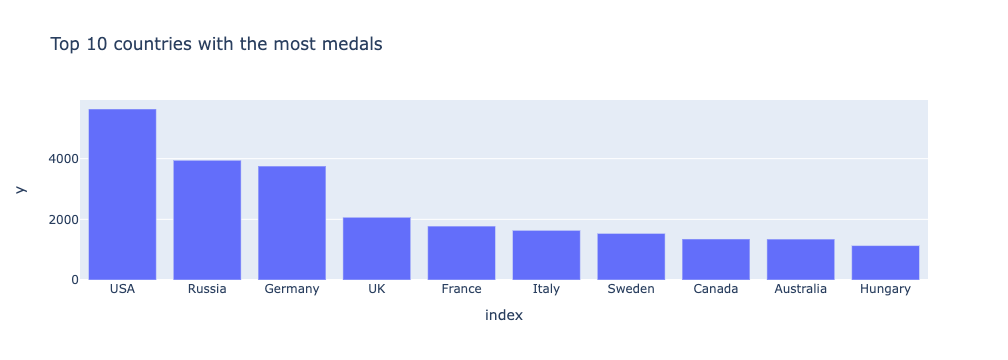

In [50]:
# Assign top 10 winningest countries table to a variable
winningestTop10_df = df["Country"].value_counts()[:10]
# Visualize the table as a bar chart
px.bar(
    winningestTop10_df,
    x=winningestTop10_df.index,
    y=winningestTop10_df.values,
    title="Top 10 countries with the most medals"
)